In [18]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler


In [19]:
titanic_data = pd.read_csv('/Users/gunay/Desktop/Pandas/Datasets/Titanic-Dataset.csv')
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [20]:
titanic_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [21]:
titanic_data.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'],axis=1, inplace=True)
titanic_data.head(3)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S


In [22]:
titanic_data['Embarked'] = titanic_data['Embarked'].fillna('S')
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].mean())
titanic_data = pd.get_dummies(titanic_data, columns=['Sex', 'Embarked'], drop_first=True)
titanic_data.head(3)

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True


In [23]:
y=titanic_data['Survived']
x=titanic_data.drop('Survived', axis=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=42)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [24]:
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

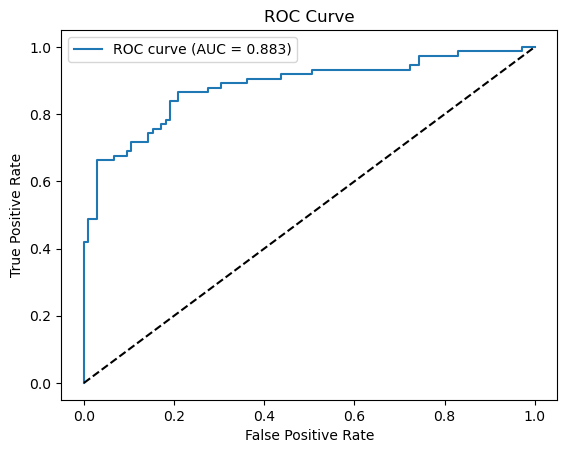

AUC: 0.883011583011583
Gini: 0.766023166023166


In [25]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


y_prob = model.predict_proba(x_test_scaled)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label='ROC curve (AUC = %0.3f)' % roc_auc_score(y_test, y_prob))
plt.plot([0, 1], [0, 1], 'k--')  # random line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


auc = roc_auc_score(y_test, y_prob)
gini = 2 * auc - 1

print("AUC:", auc)
print("Gini:", gini)

In [26]:
x_train_scaled

array([[-1.61413602,  1.22920747, -0.47072241, ...,  0.7243102 ,
        -0.30335547,  0.59248936],
       [-0.40055118, -0.50350514, -0.47072241, ...,  0.7243102 ,
        -0.30335547,  0.59248936],
       [ 0.81303367,  0.18957991, -0.47072241, ...,  0.7243102 ,
        -0.30335547,  0.59248936],
       ...,
       [ 0.81303367,  0.88266495,  1.23056874, ...,  0.7243102 ,
        -0.30335547,  0.59248936],
       [-1.61413602, -1.19659018,  0.37992316, ..., -1.38062393,
        -0.30335547,  0.59248936],
       [-1.61413602, -0.65752403, -0.47072241, ...,  0.7243102 ,
        -0.30335547,  0.59248936]])

In [27]:


df = titanic_data.copy()


df['bad'] = 1 - df['Survived']


df['Age_bin'] = pd.qcut(df['Age'], q=4, duplicates='drop')

bin_table = df.groupby('Age_bin')['bad'].agg(['count', 'sum'])
bin_table['badprob'] = bin_table['sum'] / bin_table['count']

print("\n=== BIN TABLE ===")
print(bin_table)


badprob = bin_table['badprob'].values
is_monotonic = all(x <= y for x, y in zip(badprob, badprob[1:]))

print("\nMonotonic:", is_monotonic)


total_good = (df['bad'] == 0).sum()
total_bad = (df['bad'] == 1).sum()

bin_table['good'] = bin_table['count'] - bin_table['sum']

bin_table['dist_good'] = bin_table['good'] / total_good
bin_table['dist_bad'] = bin_table['sum'] / total_bad

bin_table['woe'] = np.log(bin_table['dist_good'] / bin_table['dist_bad'])

print("\n=== WOE TABLE ===")
print(bin_table)

df = df.merge(bin_table['woe'], left_on='Age_bin', right_index=True)
df.rename(columns={'woe': 'Age_woe'}, inplace=True)

print(df[['Age', 'Age_bin', 'Age_woe']].head())


=== BIN TABLE ===
                count  sum   badprob
Age_bin                             
(0.419, 22.0]     231  133  0.575758
(22.0, 29.699]    330  220  0.666667
(29.699, 35.0]    113   62  0.548673
(35.0, 80.0]      217  134  0.617512

Monotonic: False

=== WOE TABLE ===
                count  sum   badprob  good  dist_good  dist_bad       woe
Age_bin                                                                  
(0.419, 22.0]     231  133  0.575758    98   0.286550  0.242259  0.167906
(22.0, 29.699]    330  220  0.666667   110   0.321637  0.400729 -0.219859
(29.699, 35.0]    113   62  0.548673    51   0.149123  0.112933  0.277979
(35.0, 80.0]      217  134  0.617512    83   0.242690  0.244080 -0.005711
    Age         Age_bin   Age_woe
0  22.0   (0.419, 22.0]  0.167906
1  38.0    (35.0, 80.0] -0.005711
2  26.0  (22.0, 29.699] -0.219859
3  35.0  (29.699, 35.0]  0.277979
4  35.0  (29.699, 35.0]  0.277979


In [28]:
bin_table

,count,sum,badprob,good,dist_good,dist_bad,woe
Age_bin,,,,,,,
"(0.419, 22.0]",231,133,0.575758,98,0.286550,0.242259,0.167906
"(22.0, 29.699]",330,220,0.666667,110,0.321637,0.400729,-0.219859
"(29.699, 35.0]",113,62,0.548673,51,0.149123,0.112933,0.277979
"(35.0, 80.0]",217,134,0.617512,83,0.242690,0.244080,-0.005711


In [29]:
coef = model.coef_[0]

feature_names = x.columns  # <- əsas fix

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False)

print(coef_df)

      Feature  Coefficient  Abs_Coefficient
5    Sex_male    -1.249085         1.249085
0      Pclass    -0.751360         0.751360
1         Age    -0.434976         0.434976
2       SibSp    -0.359654         0.359654
7  Embarked_S    -0.197328         0.197328
4        Fare     0.142743         0.142743
3       Parch    -0.101595         0.101595
6  Embarked_Q    -0.057246         0.057246


In [30]:
samplepassenger =pd.DataFrame([[3, 22, 1, 0, 7.25, 1, 0, 1]], columns=x.columns)
samplepassenger_scaled = scaler.transform(samplepassenger)
prediction = model.predict(samplepassenger_scaled)
prob = model.predict_proba(samplepassenger_scaled)

In [31]:
model.score(x_test_scaled, y_test)

0.8212290502793296

In [32]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84       105
           1       0.76      0.84      0.79        74

    accuracy                           0.82       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.82      0.82       179



In [33]:
y_pred.shape

(179,)

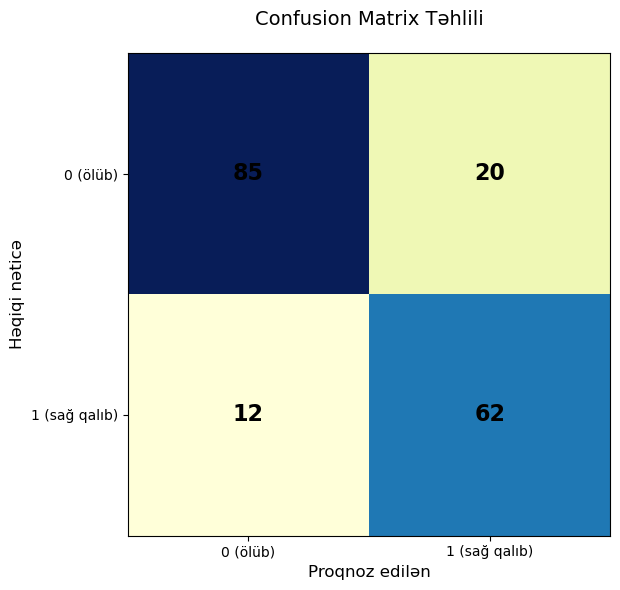

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm = cm.astype(int)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm, cmap='YlGnBu')

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = ax.text(j, i, cm[i, j],
                       ha="center", va="center", 
                       color="black", fontsize=16, fontweight='bold')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['0 (ölüb)', '1 (sağ qalıb)'])
ax.set_yticklabels(['0 (ölüb)', '1 (sağ qalıb)'])
ax.set_xlabel('Proqnoz edilən', fontsize=12)
ax.set_ylabel('Həqiqi nəticə', fontsize=12)
ax.set_title('Confusion Matrix Təhlili', fontsize=14, pad=20)

plt.tight_layout()
plt.show()